# Project 9: Optimizer Comparison Using a Neural Network

**Dataset:** Iris Classification Dataset  
**Optimizers:** Stochastic Gradient Descent (SGD) and Adam


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import SGD, Adam

np.random.seed(42)
tf.random.set_seed(42)


## Load and Prepare the Dataset

In [ ]:
iris = load_iris()

X = iris.data
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Number of features:", X_train.shape[1])
print("Number of classes:", len(np.unique(y)))


Training samples: 120
Testing samples: 30
Number of features: 4
Number of classes: 3


## Define the Neural Network

In [ ]:
def create_model():
    model = Sequential([
        Dense(16, activation="relu", input_shape=(4,)),
        Dense(8, activation="relu"),
        Dense(3, activation="softmax")
    ])

    model.compile(
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


## Train Using SGD

In [ ]:
sgd_model = create_model()

sgd_model.compile(
    optimizer=SGD(learning_rate=0.01),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

sgd_history = sgd_model.fit(
    X_train,
    y_train,
    validation_split=0.20,
    epochs=100,
    batch_size=16,
    verbose=0
)

sgd_test_loss, sgd_test_accuracy = sgd_model.evaluate(
    X_test, y_test, verbose=0
)

print(f"SGD Test Loss: {sgd_test_loss:.4f}")
print(f"SGD Test Accuracy: {sgd_test_accuracy:.4f}")


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


SGD Test Loss: 0.3060
SGD Test Accuracy: 0.9000


## Train Using Adam

In [ ]:
adam_model = create_model()

adam_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

adam_history = adam_model.fit(
    X_train,
    y_train,
    validation_split=0.20,
    epochs=100,
    batch_size=16,
    verbose=0
)

adam_test_loss, adam_test_accuracy = adam_model.evaluate(
    X_test, y_test, verbose=0
)

print(f"Adam Test Loss: {adam_test_loss:.4f}")
print(f"Adam Test Accuracy: {adam_test_accuracy:.4f}")


Adam Test Loss: 0.2151
Adam Test Accuracy: 0.9333


## Training Accuracy Comparison

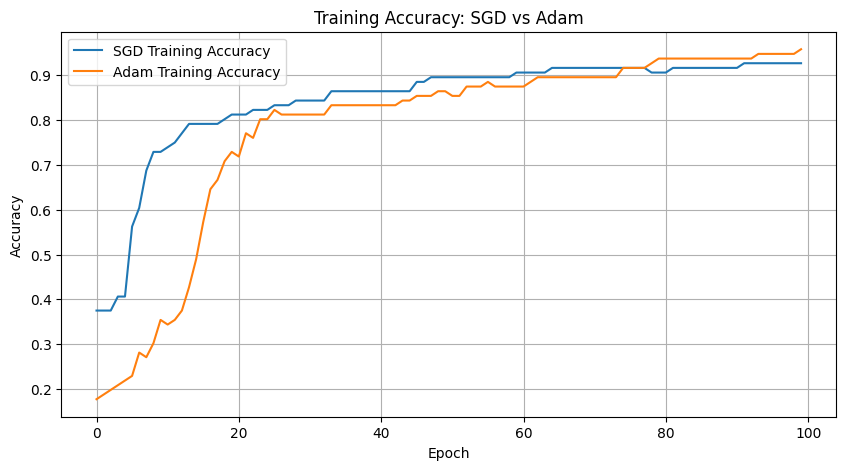

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(sgd_history.history["accuracy"], label="SGD Training Accuracy")
plt.plot(adam_history.history["accuracy"], label="Adam Training Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training Accuracy: SGD vs Adam")
plt.legend()
plt.grid(True)
plt.show()


## Validation Accuracy Comparison

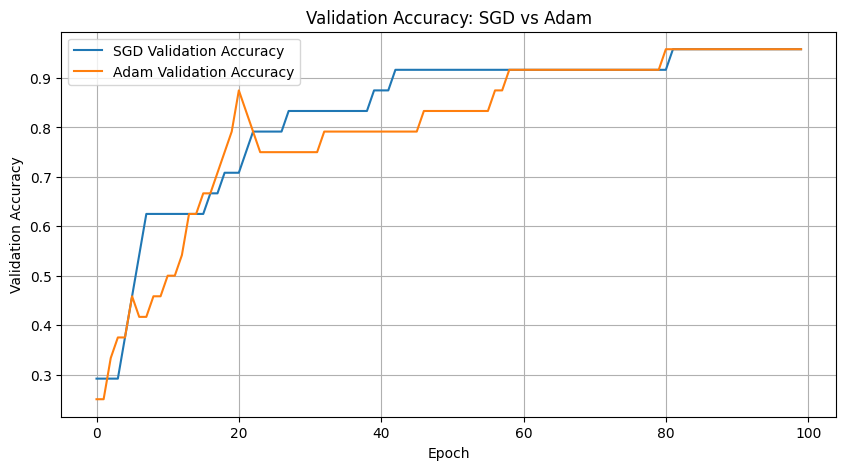

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(sgd_history.history["val_accuracy"], label="SGD Validation Accuracy")
plt.plot(adam_history.history["val_accuracy"], label="Adam Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.title("Validation Accuracy: SGD vs Adam")
plt.legend()
plt.grid(True)
plt.show()


## Training Loss Comparison

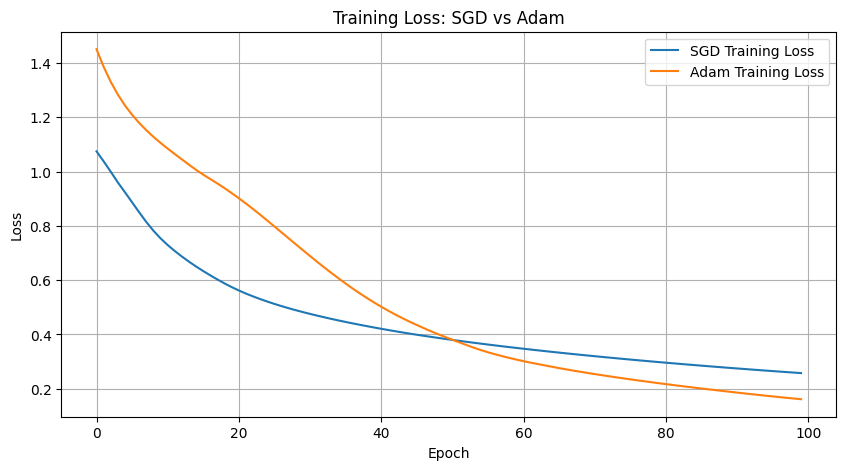

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(sgd_history.history["loss"], label="SGD Training Loss")
plt.plot(adam_history.history["loss"], label="Adam Training Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss: SGD vs Adam")
plt.legend()
plt.grid(True)
plt.show()


## Validation Loss Comparison

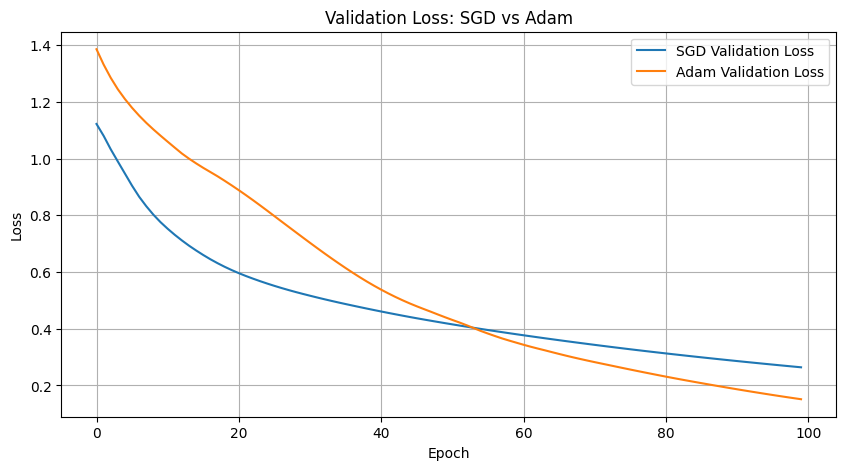

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(sgd_history.history["val_loss"], label="SGD Validation Loss")
plt.plot(adam_history.history["val_loss"], label="Adam Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Validation Loss: SGD vs Adam")
plt.legend()
plt.grid(True)
plt.show()


## Classification Performance

In [ ]:
sgd_predictions = np.argmax(sgd_model.predict(X_test, verbose=0), axis=1)
adam_predictions = np.argmax(adam_model.predict(X_test, verbose=0), axis=1)

print("SGD Classification Report")
print(classification_report(y_test, sgd_predictions, target_names=iris.target_names))

print("\nAdam Classification Report")
print(classification_report(y_test, adam_predictions, target_names=iris.target_names))


SGD Classification Report
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.70      0.82        10
   virginica       0.77      1.00      0.87        10

    accuracy                           0.90        30
   macro avg       0.92      0.90      0.90        30
weighted avg       0.92      0.90      0.90        30


Adam Classification Report
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.80      0.89        10
   virginica       0.83      1.00      0.91        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30



## Confusion Matrices

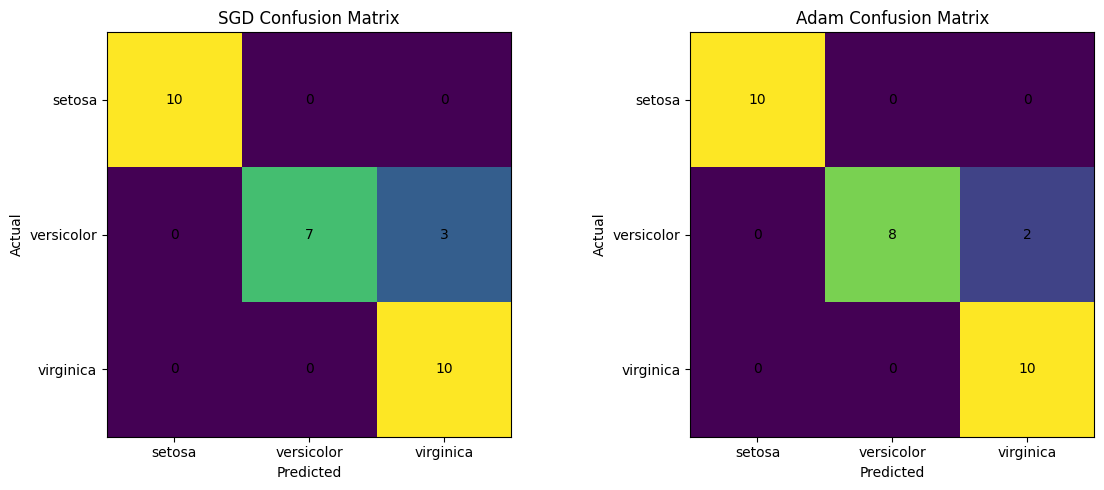

In [ ]:
sgd_cm = confusion_matrix(y_test, sgd_predictions)
adam_cm = confusion_matrix(y_test, adam_predictions)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(sgd_cm)
axes[0].set_title("SGD Confusion Matrix")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")
axes[0].set_xticks(range(3), iris.target_names)
axes[0].set_yticks(range(3), iris.target_names)

for i in range(3):
    for j in range(3):
        axes[0].text(j, i, sgd_cm[i, j], ha="center", va="center")

axes[1].imshow(adam_cm)
axes[1].set_title("Adam Confusion Matrix")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")
axes[1].set_xticks(range(3), iris.target_names)
axes[1].set_yticks(range(3), iris.target_names)

for i in range(3):
    for j in range(3):
        axes[1].text(j, i, adam_cm[i, j], ha="center", va="center")

plt.tight_layout()
plt.show()


## Optimizer Performance Comparison

In [ ]:
comparison = pd.DataFrame({
    "Optimizer": ["SGD", "Adam"],
    "Test Loss": [sgd_test_loss, adam_test_loss],
    "Test Accuracy": [sgd_test_accuracy, adam_test_accuracy]
})

comparison


,Optimizer,Test Loss,Test Accuracy
0,SGD,0.306014,0.900000
1,Adam,0.215086,0.933333


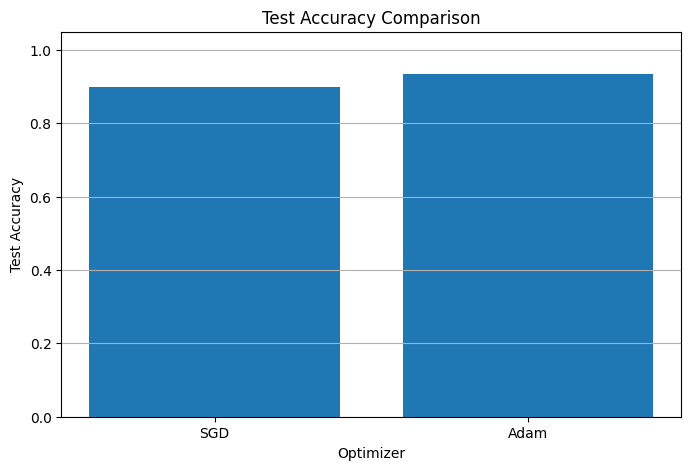

In [ ]:
plt.figure(figsize=(8, 5))

plt.bar(
    comparison["Optimizer"],
    comparison["Test Accuracy"]
)

plt.xlabel("Optimizer")
plt.ylabel("Test Accuracy")
plt.title("Test Accuracy Comparison")
plt.ylim(0, 1.05)
plt.grid(axis="y")
plt.show()


## Result

The performance of SGD and Adam was compared using the same neural network architecture, dataset split, number of epochs, and batch size.

The optimizer with the higher test accuracy provides the better classification performance for this experiment.
